In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.core.viz.style import apply_style, ITALY_C, EU_C, PEER_C
apply_style()


# Pillar 4 — Socio-Economic & Demographic Outcomes: Income Distribution, Inequality & Working-Age Attractiveness (`2008–2026`)

This notebook evaluates whether Cesena's economic trajectory translated into broad-based household prosperity and demographic vitality compared with its Emilia-Romagna peers, using two administrative panels:
1. **MEF Municipal IRPEF Declarations (`Finanze.gov.it`, tax years `2008–2024`, 17 annual waves):** Taxpayer counts and taxable/total income across the 8 statutory income brackets (`<=0`, `0–10k`, `10–15k`, `15–26k`, `26–55k`, `55–75k`, `75–120k`, `>120k` EUR) plus income composition (dependent employment, pensions, self-employment/entrepreneurship).
2. **ISTAT Demo Municipal Population by Single Year of Age (`POSAS`, `2008–2026`) & Demographic Balance (`BILANCIO`, `2008–2025`):** Resident population, old-age index (`aging_index = pop_65_plus / pop_0_14 * 100`), dependency ratio, net migration rate (internal plus international), and our **exact working-age (`25–44`) cohort net attractiveness rate** ($\text{NetCohort}_{25-44, t} = P_{25-44, t} - P_{24-43, t-1}$ per 1,000 cohort members aged `25–44`).

**Methodological notes:**
- **Bracket-creep caveat & dual Gini index:** MEF's statutory brackets are fixed in nominal euros (`0–10k` through `>120k`). Inflation pushes taxpayers into higher nominal brackets over time, so we report both the standard trapezoidal Lorentz approximation (`gini_trap`) and a **Pareto-tail-adjusted Gini (`gini_pareto`)** that corrects for top-bracket concentration, alongside real mean and interpolated median income in constant 2020 EUR.
- **Descriptive only:** All comparisons and peer rankings are descriptive.

In [2]:
from cifresignificative.studies.cesena.analysis.data import (
    load_irpef_summary, load_irpef_brackets, load_demography, load_panel_comuni,
    load_belt_comuni, cesena_vs_peers_series,
)
from cifresignificative.studies.cesena.analysis.outcomes import summarize_comprensorio_spillovers

irpef = load_irpef_summary()
brackets = load_irpef_brackets()
demo = load_demography()
panel = load_panel_comuni()
belt_df = load_belt_comuni()

print(f"MEF IRPEF summary rows: {len(irpef)} (years {irpef['year'].min()}-{irpef['year'].max()}, {irpef['comune_id'].nunique()} municipalities)")
print(f"ISTAT demography rows: {len(demo)} (years {demo['year'].min()}-{demo['year'].max()}, {demo['comune_id'].nunique()} municipalities)")
print(f"Comprensorio Cesenate (Cesena + 16 belt comuni) rows: {len(belt_df)} ({belt_df['comune_id'].nunique()} municipalities)")

MEF IRPEF summary rows: 221 (years 2008-2024, 13 municipalities)
ISTAT demography rows: 247 (years 2008-2026, 13 municipalities)
Comprensorio Cesenate (Cesena + 16 belt comuni) rows: 306 (17 municipalities)


## 1. Real Mean & Interpolated Median IRPEF Income (`2008–2024`, Constant 2020 EUR)
We compare Cesena's real mean income per positive taxpayer (`mean_income_real_eur`), real interpolated median income (`median_income_real_eur`), and real IRPEF tax base per resident (`irpef_taxbase_real_pc`) against the 6 Core Peers and all 12 Emilia-Romagna peers.

In [3]:
for col, lbl in [
    ("mean_income_real_eur", "Real mean IRPEF income per taxpayer (2020 EUR)"),
    ("median_income_real_eur", "Real interpolated median IRPEF income per taxpayer (2020 EUR)"),
    ("irpef_taxbase_real_pc", "Real total IRPEF income per resident (2020 EUR)"),
]:
    s = cesena_vs_peers_series(panel[panel["year"] <= 2024], col, core_only=True)
    print(f"\n--- {lbl} (2008-2024) ---")
    display(s[["year", "cesena", "core_peer_median", "er_peer_median", "gap_vs_benchmark", "n_core_peers", "missing_core_peers"]].round(1))

# Rank of all 13 ER municipalities in 2024 and cumulative real growth 2008-2024
inc_08 = panel[panel["year"] == 2008].set_index("comune")[["mean_income_real_eur", "median_income_real_eur", "gini_pareto"]]
inc_24 = panel[panel["year"] == 2024].set_index("comune")[["mean_income_real_eur", "median_income_real_eur", "gini_pareto", "below_15k_payer_share_pct", "top_55k_income_share_pct"]]
inc_cmp = pd.DataFrame({
    "mean_2008": inc_08["mean_income_real_eur"],
    "mean_2024": inc_24["mean_income_real_eur"],
    "mean_growth_08_24_pct": (inc_24["mean_income_real_eur"] / inc_08["mean_income_real_eur"] - 1) * 100,
    "median_2008": inc_08["median_income_real_eur"],
    "median_2024": inc_24["median_income_real_eur"],
    "median_growth_08_24_pct": (inc_24["median_income_real_eur"] / inc_08["median_income_real_eur"] - 1) * 100,
    "gini_pareto_2008": inc_08["gini_pareto"],
    "gini_pareto_2024": inc_24["gini_pareto"],
    "gini_change_pts": inc_24["gini_pareto"] - inc_08["gini_pareto"],
    "below_15k_share_2024_pct": inc_24["below_15k_payer_share_pct"],
    "top_55k_inc_share_2024_pct": inc_24["top_55k_income_share_pct"],
}).sort_values("mean_growth_08_24_pct", ascending=False)
print("\nAll 13 ER Municipalities — Real IRPEF Income Growth and Inequality (2008 vs 2024, sorted by real mean income growth):")
display(inc_cmp.round(2))


--- Real mean IRPEF income per taxpayer (2020 EUR) (2008-2024) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,22086.6,23103.6,24219.1,-1017.0,6,
1,2009,22267.4,22954.7,24122.2,-687.3,6,
2,2010,22222.8,22857.6,24087.9,-634.8,6,
3,2011,22218.5,22568.4,23714.5,-349.9,6,
4,2012,21428.1,22022.8,23136.5,-594.7,6,
5,2013,21787.3,22203.1,23466.8,-415.7,6,
6,2014,21949.5,22491.6,23575.4,-542.1,6,
7,2015,22444.3,22853.2,24093.1,-408.9,6,
8,2016,22799.5,23147.8,24370.1,-348.3,6,
9,2017,22789.5,22787.3,24389.2,2.1,6,



--- Real interpolated median IRPEF income per taxpayer (2020 EUR) (2008-2024) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,17918.2,19356.7,20323.6,-1438.5,6,
1,2009,18303.2,19519.4,20376.2,-1216.2,6,
2,2010,18209.5,19315.5,20209.9,-1105.9,6,
3,2011,18202.7,19151.1,19982.2,-948.4,6,
4,2012,17783.7,18753.0,19459.3,-969.3,6,
5,2013,18459.8,18996.1,19747.8,-536.3,6,
6,2014,18616.1,19208.7,19932.6,-592.6,6,
7,2015,18864.9,19462.1,20233.4,-597.3,6,
8,2016,19121.0,19726.0,20476.3,-605.0,6,
9,2017,18968.3,19393.4,20154.9,-425.0,6,



--- Real total IRPEF income per resident (2020 EUR) (2008-2024) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2008,17526.3,18629.5,19618.9,-1103.1,6,
1,2009,17454.0,18317.1,18854.7,-863.0,6,
2,2010,17297.6,18002.3,18543.4,-704.7,6,
3,2011,17189.5,17693.7,18165.5,-504.2,6,
4,2012,16330.4,16890.4,17501.3,-559.9,6,
5,2013,16406.9,16796.3,17362.4,-389.3,6,
6,2014,16430.4,16878.7,17333.3,-448.4,6,
7,2015,16841.8,17130.8,17756.8,-289.0,6,
8,2016,17193.8,17263.8,17893.0,-70.0,6,
9,2017,17284.9,17218.0,17869.1,66.9,6,



All 13 ER Municipalities — Real IRPEF Income Growth and Inequality (2008 vs 2024, sorted by real mean income growth):


,mean_2008,mean_2024,mean_growth_08_24_pct,median_2008,median_2024,median_growth_08_24_pct,gini_pareto_2008,gini_pareto_2024,gini_change_pts,below_15k_share_2024_pct,top_55k_inc_share_2024_pct
comune,,,,,,,,,,,
Cesena,22086.62,23138.16,4.76,17918.21,19276.51,7.58,0.41,0.39,-0.02,27.49,25.63
Faenza,22309.26,23068.53,3.40,17939.82,19167.92,6.85,0.41,0.39,-0.02,27.73,26.09
Modena,27062.02,27168.15,0.39,21275.23,21653.25,1.78,0.43,0.42,-0.01,25.33,35.71
Ferrara,24197.62,24193.49,-0.02,19982.67,20166.56,0.92,0.41,0.40,-0.01,27.46,28.82
Imola,24240.61,24182.88,-0.24,20664.54,21164.29,2.42,0.38,0.36,-0.02,24.07,24.14
Forlì,22856.53,22774.67,-0.36,19183.95,19293.95,0.57,0.40,0.38,-0.02,27.67,24.44
Ravenna,22913.18,22794.28,-0.52,19306.36,19752.66,2.31,0.40,0.37,-0.03,27.77,22.52
Rimini,20981.21,20712.89,-1.28,16721.18,16946.36,1.35,0.44,0.43,-0.01,36.90,24.90
Reggio nell'Emilia,25091.93,24684.19,-1.63,20664.66,20608.99,-0.27,0.41,0.40,-0.01,26.66,28.65


## 2. Income Inequality Across the 8 Statutory Brackets (`gini_trap` vs `gini_pareto`) & Income Sources
We examine the distribution of taxpayers and total income across the 8 MEF brackets in Cesena (`2008`, `2016`, `2024`) and compare the trajectory of the Pareto-adjusted Gini index (`gini_pareto`) and low-income taxpayer share (`<15,000 EUR`) against peers.

Cesena Positive Taxpayer Share (%) and Total Income Share (%) across the 7 Positive MEF Brackets (2008, 2016, 2024):


payer_share_pct               income_share_pct  \
tax_year                            2008   2016   2024             2008   
class_order class_label                                                   
1           0-10000                29.38  23.59  17.64             8.03   
2           10000-15000            18.38  14.81   9.84            11.95   
3           15000-26000            32.71  35.86  31.51            33.08   
4           26000-55000            15.72  21.09  34.07            27.93   
5           55000-75000             1.82   2.22   3.19             5.95   
6           75000-120000            1.38   1.62   2.44             6.49   
7           > 120000                0.62   0.82   1.31             6.57   

                                        
tax_year                   2016   2024  
class_order class_label                 
1           0-10000        5.34   2.90  
2           10000-15000    8.42   4.53  
3           15000-26000   32.75  24.00  
4           26000-55000   32.81  42.95  
5           55000-75000    6.39   7.39  
6           75000-120000   6.71   8.26  
7           > 120000       7.58   9.97


--- Pareto-adjusted Gini index across 8 IRPEF brackets ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark
0,2008,0.408,0.399,0.409,0.009
4,2012,0.403,0.392,0.408,0.011
8,2016,0.397,0.393,0.409,0.004
11,2019,0.395,0.395,0.412,-0.000
13,2021,0.399,0.399,0.415,0.000
16,2024,0.386,0.379,0.397,0.007



--- Trapezoidal lower-bound Gini index across 8 IRPEF brackets ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark
0,2008,0.408,0.399,0.409,0.009
4,2012,0.403,0.392,0.408,0.011
8,2016,0.396,0.393,0.409,0.004
11,2019,0.395,0.395,0.412,-0.000
13,2021,0.399,0.399,0.415,0.000
16,2024,0.385,0.378,0.397,0.007



--- Taxpayers declaring <15,000 EUR (% of positive taxpayers) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark
0,2008,47.754,43.464,41.008,4.290
4,2012,43.677,40.566,38.559,3.112
8,2016,38.397,36.728,35.030,1.669
11,2019,35.913,35.104,34.008,0.809
13,2021,34.217,33.652,32.802,0.564
16,2024,27.485,27.430,26.994,0.055



--- Share of total IRPEF income held by >55,000 EUR brackets (%) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark
0,2008,19.011,18.904,20.696,0.107
4,2012,19.538,18.660,21.073,0.877
8,2016,20.680,20.241,22.740,0.439
11,2019,21.291,21.037,23.860,0.253
13,2021,23.259,22.831,25.545,0.428
16,2024,25.626,24.288,27.369,1.338


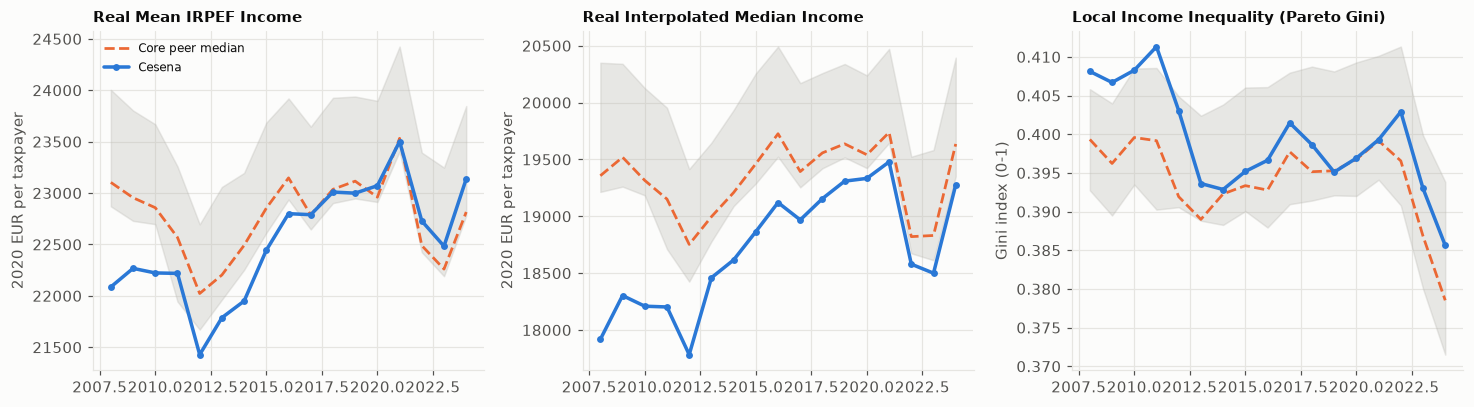

In [4]:
ces_b = brackets[(brackets["comune_id"] == "040007") & (brackets["tax_year"].isin([2008, 2016, 2024])) & (brackets["class_order"] >= 1)].copy()
ces_b["payer_share_pct"] = ces_b.groupby("tax_year")["taxpayers"].transform(lambda s: s / s.sum() * 100)
ces_b["income_share_pct"] = ces_b.groupby("tax_year")["income_eur"].transform(lambda s: s / s.sum() * 100)
piv_b = ces_b.pivot(index=["class_order", "class_label"], columns="tax_year", values=["payer_share_pct", "income_share_pct"])
print("Cesena Positive Taxpayer Share (%) and Total Income Share (%) across the 7 Positive MEF Brackets (2008, 2016, 2024):")
display(piv_b.round(2))

for col, lbl in [
    ("gini_pareto", "Pareto-adjusted Gini index across 8 IRPEF brackets"),
    ("gini_trap", "Trapezoidal lower-bound Gini index across 8 IRPEF brackets"),
    ("below_15k_payer_share_pct", "Taxpayers declaring <15,000 EUR (% of positive taxpayers)"),
    ("top_55k_income_share_pct", "Share of total IRPEF income held by >55,000 EUR brackets (%)"),
]:
    s = cesena_vs_peers_series(panel[panel["year"] <= 2024], col, core_only=True)
    print(f"\n--- {lbl} ---")
    display(s[s["year"].isin([2008, 2012, 2016, 2019, 2021, 2024])][["year", "cesena", "core_peer_median", "er_peer_median", "gap_vs_benchmark"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for ax, (col, title, yl) in zip(axes, [
    ("mean_income_real_eur", "Real Mean IRPEF Income", "2020 EUR per taxpayer"),
    ("median_income_real_eur", "Real Interpolated Median Income", "2020 EUR per taxpayer"),
    ("gini_pareto", "Local Income Inequality (Pareto Gini)", "Gini index (0-1)"),
]):
    s = cesena_vs_peers_series(panel[panel["year"] <= 2024], col, core_only=True)
    ax.plot(s["year"], s["core_peer_median"], color=EU_C, ls="--", lw=1.8, label="Core peer median")
    ax.fill_between(s["year"], s["core_peer_p25"], s["core_peer_p75"], color=PEER_C, alpha=0.3)
    ax.plot(s["year"], s["cesena"], color=ITALY_C, lw=2.3, marker="o", ms=3.5, label="Cesena")
    ax.set_title(title, fontsize=9.5)
    ax.set_ylabel(yl)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Demographic Vitality: Population, Aging Index, and Working-Age (`25–44`) Cohort Net Attractiveness (`2008–2026`)
Because municipal migration registers do not publish age-specific inflows/outflows across the entire 2008–2025 span, we measure young-adult demographic attractiveness directly from the exact single-year-of-age population register (`POSAS`):
$$\text{NetCohort}_{25-44, t} = P_{25-44, t} - P_{24-43, t-1}$$
Since mortality between ages 24 and 44 is below 0.6 per 1,000, this cohort survival difference captures net migration of 25–44 year-olds per 1,000 cohort members aged `25–44` (`net_cohort_25_44_per_1k`). It also contains census and registry revisions, which are not migration (for example 2012–2013 and 2020–2021; `net_cohort_25_44_3y_ma` smooths single years), so read it by sub-period (Section 8).


--- Total resident population (Jan 1, 2008-2026) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers
0,2008,94463,124885.0,134121.0,-30422.0,6
3,2011,96317,128889.5,137404.5,-32572.5,6
6,2014,97006,131589.5,139259.0,-34583.5,6
9,2017,96344,132633.5,139885.5,-36289.5,6
11,2019,97421,133670.5,140956.0,-36249.5,6
13,2021,96520,133823.5,140954.5,-37303.5,6
15,2023,96003,133203.5,139702.5,-37200.5,6
17,2025,95730,133934.0,139707.0,-38204.0,6
18,2026,95620,134413.5,139911.0,-38793.5,6



--- Old-age / aging index (65+ per 100 aged 0-14) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers
0,2008,184.85,175.09,189.72,9.76,6
3,2011,179.66,171.83,179.89,7.83,6
6,2014,181.62,177.08,180.16,4.53,6
9,2017,193.62,181.27,183.63,12.35,6
11,2019,199.97,185.94,186.92,14.03,6
13,2021,207.72,192.29,188.16,15.43,6
15,2023,220.68,202.63,198.37,18.05,6
17,2025,237.46,217.88,214.01,19.58,6
18,2026,248.66,226.40,221.24,22.26,6



--- Working-age 25-44 cohort share of population (%) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers
0,2008,29.66,29.62,29.14,0.05,6
3,2011,27.70,27.94,27.85,-0.24,6
6,2014,25.82,26.27,25.97,-0.46,6
9,2017,23.60,24.74,24.48,-1.14,6
11,2019,22.80,23.77,24.03,-0.97,6
13,2021,21.86,22.85,23.39,-0.99,6
15,2023,21.23,22.25,22.79,-1.02,6
17,2025,20.97,22.13,22.85,-1.16,6
18,2026,21.03,22.27,22.96,-1.24,6


... (2 outputs left out)


--- 25-44 working-age cohort net attractiveness per 1,000 cohort members ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers
0,2008,8.74,23.32,25.55,-14.57,6
3,2011,9.97,12.17,12.17,-2.20,6
6,2014,-5.67,6.39,7.32,-12.06,6
9,2017,14.07,10.15,14.11,3.92,6
11,2019,11.66,10.73,11.50,0.93,6
13,2021,7.54,2.63,0.70,4.91,6
15,2023,14.18,18.10,17.65,-3.92,6
17,2025,13.70,21.96,16.59,-8.26,6
18,2026,NaN,NaN,NaN,NaN,0



All 13 ER Municipalities — Demographic Trajectory & 25-44 Cohort Attractiveness (2008-2025):


,pop_2008,pop_2025,pop_change_08_25_pct,aging_2008,aging_2025,aging_change_pts,share_25_44_2025_pct,mean_net_migr_14_25_per_1k,mean_25_44_attract_14_25_per_1k
comune,,,,,,,,,
Bologna,365983,390151,6.60,259.23,221.34,-37.88,26.90,8.61,20.34
Carpi,64870,73297,12.99,162.67,192.55,29.88,23.38,8.89,19.75
Parma,172138,198693,15.43,195.52,183.52,-12.00,25.64,10.74,18.91
Modena,177471,184074,3.72,174.64,205.76,31.12,23.74,6.35,13.45
Ferrara,132439,129081,-2.54,269.52,300.17,30.65,20.75,7.53,13.38
Rimini,135803,150333,10.70,166.35,218.38,52.03,22.31,7.69,13.01
Piacenza,98261,103406,5.24,210.01,196.85,-13.16,23.78,7.30,12.09
Forlì,113967,117535,3.13,194.71,219.62,24.91,21.95,6.69,12.08
Imola,66703,69403,4.05,183.83,217.38,33.55,21.94,6.77,11.93


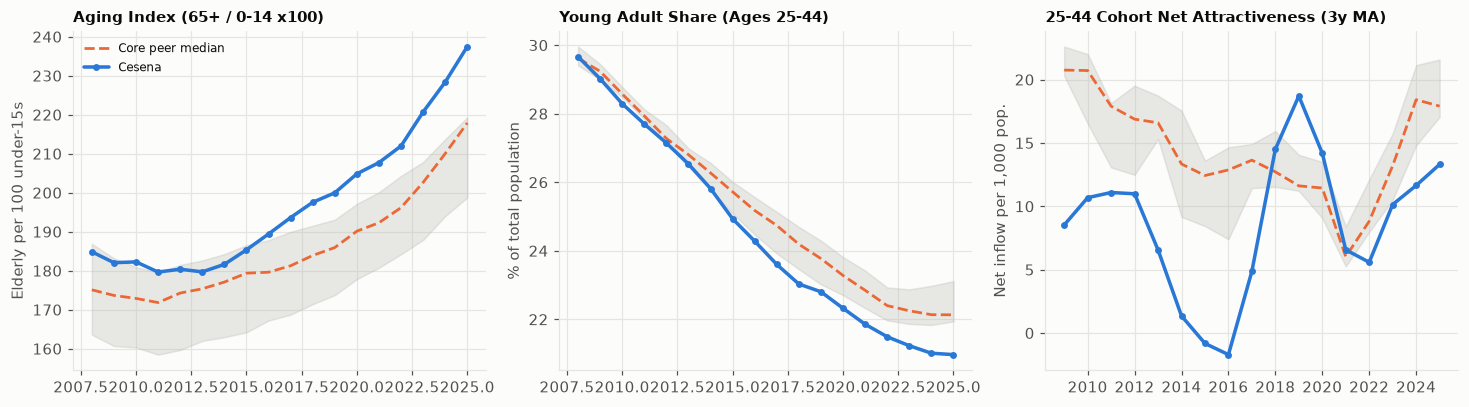

In [5]:
for col, lbl in [
    ("pop_total", "Total resident population (Jan 1, 2008-2026)"),
    ("aging_index", "Old-age / aging index (65+ per 100 aged 0-14)"),
    ("share_25_44_pct", "Working-age 25-44 cohort share of population (%)"),
    ("net_migr_rate_per_1k", "Total net migration rate per 1,000 residents"),
    ("net_cohort_25_44_per_1k", "25-44 working-age cohort net attractiveness per 1,000 cohort members"),
]:
    s = cesena_vs_peers_series(demo, col, core_only=True)
    print(f"\n--- {lbl} ---")
    display(s[s["year"].isin([2008, 2011, 2014, 2017, 2019, 2021, 2023, 2025, 2026])][
        ["year", "cesena", "core_peer_median", "er_peer_median", "gap_vs_benchmark", "n_core_peers"]
    ].round(2))

dem_08 = demo[demo["year"] == 2008].set_index("comune")
dem_25 = demo[demo["year"] == 2025].set_index("comune")
cohort_mean = demo[demo["year"].between(2014, 2025)].groupby("comune")["net_cohort_25_44_per_1k"].mean()
migr_mean = demo[demo["year"].between(2014, 2025)].groupby("comune")["net_migr_rate_per_1k"].mean()
dem_cmp = pd.DataFrame({
    "pop_2008": dem_08["pop_total"],
    "pop_2025": dem_25["pop_total"],
    "pop_change_08_25_pct": (dem_25["pop_total"] / dem_08["pop_total"] - 1) * 100,
    "aging_2008": dem_08["aging_index"],
    "aging_2025": dem_25["aging_index"],
    "aging_change_pts": dem_25["aging_index"] - dem_08["aging_index"],
    "share_25_44_2025_pct": dem_25["share_25_44_pct"],
    "mean_net_migr_14_25_per_1k": migr_mean,
    "mean_25_44_attract_14_25_per_1k": cohort_mean,
}).sort_values("mean_25_44_attract_14_25_per_1k", ascending=False)
print("\nAll 13 ER Municipalities — Demographic Trajectory & 25-44 Cohort Attractiveness (2008-2025):")
display(dem_cmp.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for ax, (col, title, yl) in zip(axes, [
    ("aging_index", "Aging Index (65+ / 0-14 x100)", "Elderly per 100 under-15s"),
    ("share_25_44_pct", "Young Adult Share (Ages 25-44)", "% of total population"),
    ("net_cohort_25_44_3y_ma", "25-44 Cohort Net Attractiveness (3y MA)", "Net inflow per 1,000 pop."),
]):
    s = cesena_vs_peers_series(demo[demo["year"] <= 2025], col, core_only=True)
    ax.plot(s["year"], s["core_peer_median"], color=EU_C, ls="--", lw=1.8, label="Core peer median")
    ax.fill_between(s["year"], s["core_peer_p25"], s["core_peer_p75"], color=PEER_C, alpha=0.3)
    ax.plot(s["year"], s["cesena"], color=ITALY_C, lw=2.3, marker="o", ms=3.5, label="Cesena")
    ax.set_title(title, fontsize=9.5)
    ax.set_ylabel(yl)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Cesena and the 16 Surrounding Municipalities (`Comprensorio Cesenate`, a study definition, `2008–2025`)
Population, jobs and income are compared across three rings. Note that the periods differ between series (population from 2008, ASIA jobs from 2012), and that Bertinoro and Forlimpopoli belong to another Unione. Section 8 gives the population change by component in matching periods.
- **Unione Rubicone e Mare (`9` municipalities:** Cesenatico, Gambettola, Gatteo, Longiano, San Mauro Pascoli, Savignano sul Rubicone, Borghi, Roncofreddo, Sogliano al Rubicone);
- **Via Emilia West corridor (`2` municipalities:** Forlimpopoli, Bertinoro);
- **Unione dei Comuni Valle del Savio (`5` municipalities:** Bagno di Romagna, Mercato Saraceno, Montiano, Sarsina, Verghereto).

Comprensorio Cesenate (Cesena + 16 surrounding municipalities) — Population, Net Migration, ASIA Employment, Real Income & Tax Surcharges by Functional Ring:


,belt_label,n_comuni,pop_2008,pop_2025,pop_delta_08_25,pop_growth_08_25_pct,net_migration_08_24,natural_balance_08_24,emp_2012,emp_2024,emp_delta_12_24,emp_growth_12_24_pct,emp_per_1k_pop_2012,emp_per_1k_pop_2024,mean_income_real_2008,mean_income_real_2024,real_income_growth_08_24_pct,effective_addizionale_rate_2024_pct,addizionale_real_pc_2024
0,Cesena (core municipality),1,94463.0,95730.0,1267.0,1.34,9335.0,-6549.0,36760.37,42192.02,5431.65,14.78,380.41,439.20,22086.62,23138.16,4.76,0.42,75.40
1,Unione Rubicone e Mare (coastal/industrial belt),9,84712.0,93549.0,8837.0,10.43,10609.0,-905.0,34333.74,34808.91,475.17,1.38,380.24,373.09,19167.22,19590.42,2.21,0.50,77.79
2,Via Emilia West (Forlimpopoli & Bertinoro),2,22856.0,24265.0,1409.0,6.16,2513.0,-902.0,7456.76,7562.41,105.65,1.42,309.82,312.96,20812.24,21731.78,4.42,0.45,76.86
3,Unione Valle del Savio (mountain/hill belt),5,20080.0,19144.0,-936.0,-4.66,1090.0,-1721.0,5958.62,5732.76,-225.86,-3.79,291.18,298.89,18100.21,19759.07,9.16,0.64,100.75
4,All 16 surrounding belt municipalities,16,127648.0,136958.0,9310.0,7.29,14212.0,-3528.0,47749.12,48104.08,354.96,0.74,354.15,352.04,19299.34,19989.87,3.58,0.51,80.85
5,Full Comprensorio Cesenate (Cesena + 16 belt c...,17,222111.0,232688.0,10577.0,4.76,23547.0,-10077.0,84509.49,90296.10,5786.61,6.85,365.11,388.02,20482.74,21283.32,3.91,0.47,78.60



All 17 Municipalities of the Comprensorio Cesenate (sorted by 2008-2025 population growth %):


,comune_id,comune,belt_group,pop_2008,pop_2025,pop_growth_08_25_pct,net_migration_08_24,emp_2012,emp_2024,emp_delta_12_24,emp_growth_12_24_pct,emp_per_1k_pop_2024,mean_income_real_2024,real_income_growth_08_24_pct,effective_addizionale_rate_2024_pct,addizionale_real_pc_2024
0,040004,Borghi,rubicone_mare,2364.0,2910.0,23.10,521.0,307.13,428.14,121.01,39.40,148.45,17810.10,4.96,0.37,50.47
1,040041,San Mauro Pascoli,rubicone_mare,10503.0,12386.0,17.93,1940.0,5078.20,5097.32,19.12,0.38,414.58,19629.02,0.89,0.51,77.95
2,040016,Gatteo,rubicone_mare,8048.0,9417.0,17.01,1197.0,3639.64,4505.37,865.73,23.79,478.48,19368.74,11.05,0.51,77.07
3,040018,Longiano,rubicone_mare,6536.0,7247.0,10.88,779.0,3270.44,3119.99,-150.45,-4.60,429.16,21021.13,-5.34,0.46,73.28
4,040003,Bertinoro,via_emilia_west,10172.0,11102.0,9.14,1086.0,4088.82,4102.18,13.36,0.33,369.93,21797.14,5.13,0.49,84.49
5,040015,Gambettola,rubicone_mare,9971.0,10874.0,9.06,1167.0,3406.38,3208.61,-197.77,-5.81,296.65,20037.08,3.76,0.50,77.45
6,040008,Cesenatico,rubicone_mare,24168.0,26060.0,7.83,3155.0,11208.62,10610.05,-598.57,-5.34,407.95,19352.78,6.55,0.59,94.77
7,040045,Savignano sul Rubicone,rubicone_mare,16736.0,18028.0,7.72,1278.0,6080.62,6523.89,443.27,7.29,362.50,19726.84,-6.43,0.44,66.75
8,040037,Roncofreddo,rubicone_mare,3308.0,3485.0,5.35,316.0,622.53,569.22,-53.31,-8.56,164.85,19306.18,3.46,0.69,109.38
9,040013,Forlimpopoli,via_emilia_west,12684.0,13163.0,3.78,1427.0,3367.94,3460.23,92.29,2.74,264.64,21675.84,3.82,0.42,70.38


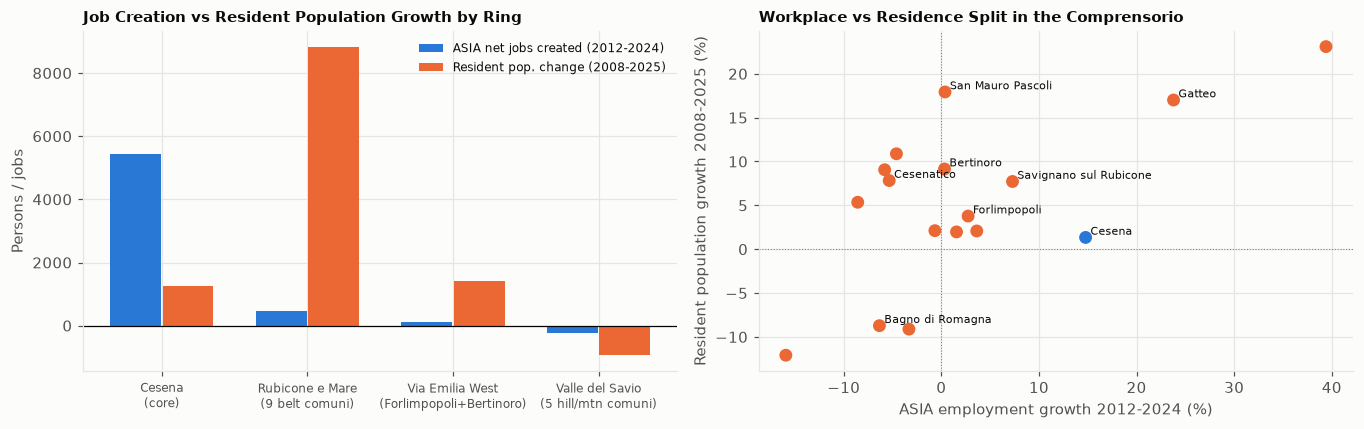

In [6]:
by_grp, by_muni = summarize_comprensorio_spillovers(belt_df)
print("Comprensorio Cesenate (Cesena + 16 surrounding municipalities) — Population, Net Migration, ASIA Employment, Real Income & Tax Surcharges by Functional Ring:")
display(by_grp[[
    "belt_label", "n_comuni", "pop_2008", "pop_2025", "pop_delta_08_25", "pop_growth_08_25_pct",
    "net_migration_08_24", "natural_balance_08_24",
    "emp_2012", "emp_2024", "emp_delta_12_24", "emp_growth_12_24_pct",
    "emp_per_1k_pop_2012", "emp_per_1k_pop_2024",
    "mean_income_real_2008", "mean_income_real_2024", "real_income_growth_08_24_pct",
    "effective_addizionale_rate_2024_pct", "addizionale_real_pc_2024",
]].round(2))

print("\nAll 17 Municipalities of the Comprensorio Cesenate (sorted by 2008-2025 population growth %):")
display(by_muni[[
    "comune_id", "comune", "belt_group", "pop_2008", "pop_2025", "pop_growth_08_25_pct",
    "net_migration_08_24", "emp_2012", "emp_2024", "emp_delta_12_24", "emp_growth_12_24_pct",
    "emp_per_1k_pop_2024", "mean_income_real_2024", "real_income_growth_08_24_pct",
    "effective_addizionale_rate_2024_pct", "addizionale_real_pc_2024",
]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
ring_sub = by_grp[by_grp["belt_group"].isin(["cesena_core", "rubicone_mare", "via_emilia_west", "unione_valle_savio"])].copy()
short_lbls = ["Cesena\n(core)", "Rubicone e Mare\n(9 belt comuni)", "Via Emilia West\n(Forlimpopoli+Bertinoro)", "Valle del Savio\n(5 hill/mtn comuni)"]
x = range(len(ring_sub))
axes[0].bar([i - 0.18 for i in x], ring_sub["emp_delta_12_24"], width=0.35, color=ITALY_C, label="ASIA net jobs created (2012-2024)")
axes[0].bar([i + 0.18 for i in x], ring_sub["pop_delta_08_25"], width=0.35, color=EU_C, label="Resident pop. change (2008-2025)")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xticks(list(x), short_lbls, fontsize=8)
axes[0].set_title("Job Creation vs Resident Population Growth by Ring", fontsize=9.5)
axes[0].set_ylabel("Persons / jobs")
axes[0].legend(fontsize=8)

axes[1].scatter(by_muni["emp_growth_12_24_pct"], by_muni["pop_growth_08_25_pct"], c=[ITALY_C if c == "040007" else EU_C for c in by_muni["comune_id"]], s=55)
for _, r in by_muni.iterrows():
    if r["comune_id"] in ("040007", "040041", "040016", "040008", "040013", "040003", "040001", "040045"):
        axes[1].annotate(str(r["comune"]), (float(r["emp_growth_12_24_pct"]) + 0.5, float(r["pop_growth_08_25_pct"]) + 0.3), fontsize=7.5)
axes[1].axhline(0, color="gray", lw=0.7, ls=":")
axes[1].axvline(0, color="gray", lw=0.7, ls=":")
axes[1].set_xlabel("ASIA employment growth 2012-2024 (%)")
axes[1].set_ylabel("Resident population growth 2008-2025 (%)")
axes[1].set_title("Workplace vs Residence Split in the Comprensorio", fontsize=9.5)
plt.tight_layout()
plt.show()

## 5. Higher Education: UniBo Cesena Campus (MUR USTAT, `2010–2026`)
Students, graduates and subject mix (STEM, ICT, engineering, psychology) across the 13 municipalities, from the **Ministry of University and Research (MUR USTAT)**. Whether graduates stay and work locally is not measured.

In [7]:
from cifresignificative.studies.cesena.analysis.data import load_university_summary, load_university_enrolments
from cifresignificative.studies.cesena.analysis.outcomes import summarize_university_benchmarks

uni_sum = load_university_summary()
uni_enr = load_university_enrolments()

print("Emilia-Romagna University Poles — Enrolments, STEM & ICT Shares (2024/2025):")
y24 = uni_sum[uni_sum["calendar_year"] == 2024].sort_values("stem_share", ascending=False)
display(y24[["comune_name", "students_total", "stem_share", "ict_share", "engineering_share", "psychology_share", "graduates_total"]].round(3))

bench_uni = summarize_university_benchmarks(uni_sum, demo, core_only=False, year=2024)
print("\nCesena vs All-ER Peer Median on University Metrics (2024):")
display(bench_uni[["label", "formatted_cesena", "formatted_peer", "gap_pct"]].rename(columns={"formatted_cesena": "Cesena", "formatted_peer": "ER Peer Median", "gap_pct": "Gap vs Peer (%)"}).round(1))

ces_u = uni_sum[uni_sum["comune_id"] == "040007"].sort_values("calendar_year")
print("\nCesena University Trajectory (2010-2025):")
display(ces_u[["calendar_year", "students_total", "students_stem", "students_ict", "students_engineering", "students_psychology", "stem_share", "ict_share", "graduates_total"]].round(3))

Emilia-Romagna University Poles — Enrolments, STEM & ICT Shares (2024/2025):


,comune_name,students_total,stem_share,ict_share,engineering_share,psychology_share,graduates_total
172,Carpi,36,1.000,0.000,1.000,0.000,NaN
175,Imola,528,0.676,0.000,0.013,0.000,129.0
179,Cesena,4706,0.665,0.137,0.424,0.312,1106.0
173,Modena,16078,0.426,0.030,0.282,0.000,3632.0
170,Parma,29559,0.348,0.021,0.159,0.025,5864.0
176,Ferrara,26391,0.306,0.020,0.097,0.000,5141.0
169,Piacenza,4669,0.300,0.000,0.212,0.000,1263.0
174,Bologna,63669,0.299,0.021,0.154,0.003,14970.0
178,Ravenna,3418,0.250,0.000,0.134,0.000,685.0
171,Reggio nell'Emilia,9381,0.213,0.000,0.167,0.106,2067.0



Cesena vs All-ER Peer Median on University Metrics (2024):


,label,Cesena,ER Peer Median,Gap vs Peer (%)
0,Total University Students Enrolled,"4,706","5,628",-16.4
1,"University Students per 1,000 Inhabitants",49.0,50.1,-2.2
2,STEM Student Share (% of total enrolments),66.5%,29.9%,122.2
3,Computer Science / ICT Share (% of enrolments),13.7%,0.0%,NaN
4,Engineering Share (% of enrolments),42.4%,15.6%,171.1
5,Psychology Share (% of enrolments),31.2%,0.0%,NaN
6,Total Annual University Graduates,"1,106","1,746",-36.7
7,"Graduates per 1,000 Inhabitants",11.5,12.3,-6.2



Cesena University Trajectory (2010-2025):


,calendar_year,students_total,students_stem,students_ict,students_engineering,students_psychology,stem_share,ict_share,graduates_total
9,2010,4278,2672,416,1806,1606,0.625,0.097,873.0
21,2011,4387,2758,473,1794,1629,0.629,0.108,809.0
33,2012,4466,2875,489,1829,1591,0.644,0.109,802.0
45,2013,4463,2877,444,1787,1586,0.645,0.099,859.0
57,2014,4415,2852,395,1793,1563,0.646,0.089,868.0
69,2015,4315,2833,375,1785,1482,0.657,0.087,929.0
81,2016,4207,2801,359,1775,1406,0.666,0.085,1057.0
93,2017,4283,2903,396,1826,1380,0.678,0.092,1019.0
105,2018,4256,2898,407,1793,1358,0.681,0.096,968.0
117,2019,4206,2918,435,1785,1288,0.694,0.103,1107.0


## 6. Housing Prices and the Suburbanisation Hypothesis (Agenzia delle Entrate OMI)

Suburbanisation driven by housing cost is a **hypothesis** here, not a result (research track R2). OMI quotations are one cross-section, averaged across zones without weights; zones with no rental quote are treated as missing.
- **Purchase quotations (€/m²)** across `Abitazioni civili` and `Abitazioni di tipo economico`.
- **Rents (€/m²/month).**
- **Price-to-income and rent burden**, using mean declared income, which is by place of residence.
- **Price differences against Cesena.** Section 8 reports the test: if cheap housing drew residents, cheaper towns should have grown more.

1. Comprensorio Cesenate Housing Cost Gradient by Functional Ring:


,belt_label,n_municipalities,compr_mid_median_eur_m2,loc_mid_median_eur_mo,price_diff_vs_cesena_pct_median,rent_diff_vs_cesena_pct_median,price_to_income_ratio_median,rent_burden_pct_median,annual_rent_savings_80m2_median_eur,purchase_savings_100m2_median_eur,pop_growth_08_25_pct_median,net_migr_rate_2024_median
0,Cesena (core municipality),1,1588.14,5.56,0.00,0.00,5.79,19.44,0.00,0.00,1.34,4.10
1,Unione Rubicone e Mare (coastal/industrial belt),9,1465.74,4.95,-7.71,-10.87,7.32,23.72,579.87,12239.65,9.06,6.39
2,Via Emilia West (Forlimpopoli & Bertinoro),2,1428.93,4.82,-10.02,-13.17,6.57,21.31,702.56,15920.87,6.46,7.54
3,Unione Valle del Savio (mountain/hill belt),5,1179.38,4.00,-25.74,-27.93,5.85,19.10,1489.65,40876.23,-8.72,4.02



2. Cesena vs. 12 Emilia-Romagna Peer Municipalities on Housing Costs & Affordability:


,metric,metric_label,cesena_value,core_peer_median,all_er_median,cesena_rank_1_to_13,gap_vs_core,gap_vs_all
0,compr_mid_eur_m2,Residential Purchase Price (€/m²),1588.14,1561.71,1500.37,3,26.43,87.77
1,loc_mid_eur_m2_mo,Residential Monthly Rent (€/m²/month),5.56,5.50,5.50,6,0.06,0.06
2,price_to_income_ratio_100m2,Price-to-Income Ratio (100 m² apartment / Mean...,5.79,5.61,4.71,5,0.17,1.08
3,gross_rental_yield_pct,Gross Rental Yield (%),4.20,4.32,4.32,10,-0.12,-0.12



3. Housing Costs across All 17 Municipalities of the Comprensorio Cesenate (sorted by purchase price):


,comune_name,belt_group,compr_mid_eur_m2,diff_vs_cesena_pct,loc_mid_eur_m2_mo,diff_rent_vs_cesena_pct,price_to_income_ratio_100m2,rent_burden_pct_80m2,annual_rent_savings_vs_cesena_eur,purchase_savings_100m2_vs_cesena_eur,pop_growth_08_25_pct
14,Cesenatico,rubicone_mare,2679.29,68.71,10.41,87.43,13.84,51.66,-4663.38,-109114.85,7.83
16,Gatteo,rubicone_mare,1619.17,1.95,6.10,9.73,8.36,30.22,-519.15,-3102.94,17.01
0,Cesena,cesena_core,1588.14,0.00,5.56,0.00,5.79,19.44,0.00,0.00,1.34
19,San Mauro Pascoli,rubicone_mare,1536.46,-3.25,5.62,1.15,7.83,27.48,-61.35,5167.89,17.93
20,Savignano sul Rubicone,rubicone_mare,1533.80,-3.42,5.56,0.08,7.78,27.06,-4.13,5434.10,7.72
15,Gambettola,rubicone_mare,1465.74,-7.71,4.95,-10.87,7.32,23.72,579.87,12239.65,9.06
28,Forlimpopoli,via_emilia_west,1457.86,-8.20,4.93,-11.24,6.73,21.84,599.48,13028.01,3.78
17,Longiano,rubicone_mare,1400.69,-11.80,4.69,-15.53,6.66,21.43,828.31,18744.28,10.88
27,Bertinoro,via_emilia_west,1400.00,-11.85,4.72,-15.10,6.42,20.77,805.65,18813.73,9.14
23,Mercato Saraceno,unione_valle_savio,1229.67,-22.57,4.17,-24.94,6.09,19.82,1330.45,35847.06,1.97


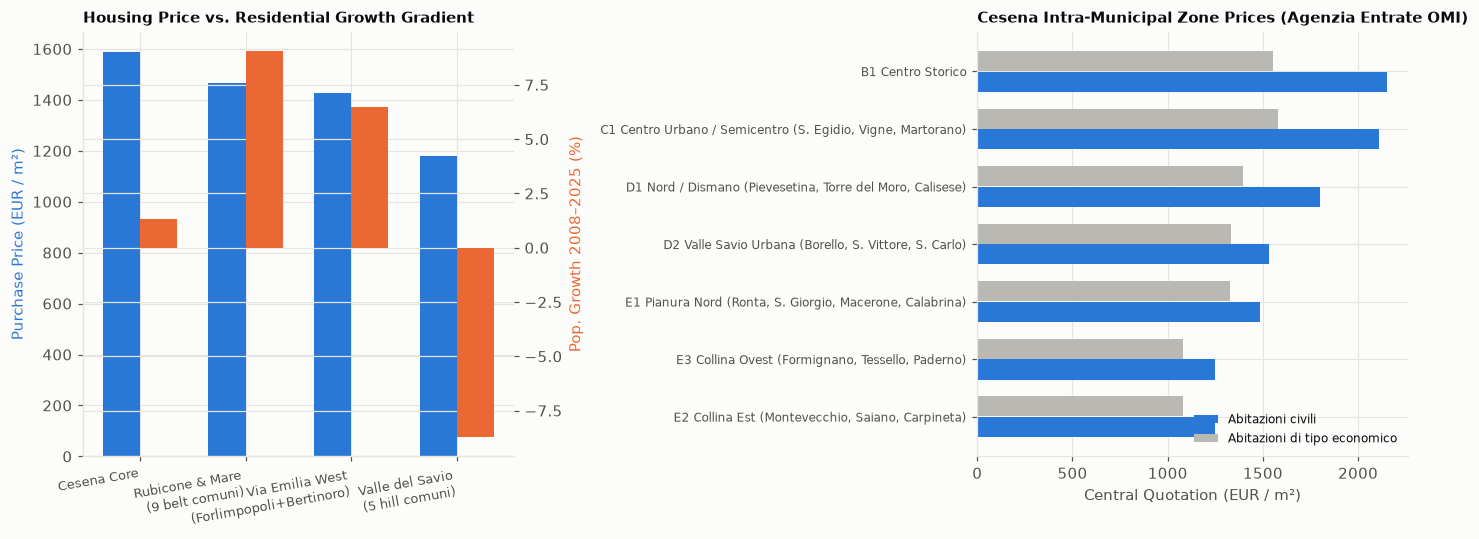

In [8]:
from cifresignificative.studies.cesena.analysis.data import (
    load_omi_municipal, load_omi_zones, load_omi_transactions,
)
from cifresignificative.studies.cesena.analysis.housing import (
    compute_housing_affordability, comprensorio_housing_gradient, peer_housing_comparison,
)

omi_muni = load_omi_municipal()
omi_zones = load_omi_zones()
omi_trans = load_omi_transactions()

affordability = compute_housing_affordability(omi_muni, irpef, demo)
gradient = comprensorio_housing_gradient(affordability)
peer_housing = peer_housing_comparison(affordability)

print("1. Comprensorio Cesenate Housing Cost Gradient by Functional Ring:")
display(gradient[[
    "belt_label", "n_municipalities", "compr_mid_median_eur_m2", "loc_mid_median_eur_mo",
    "price_diff_vs_cesena_pct_median", "rent_diff_vs_cesena_pct_median",
    "price_to_income_ratio_median", "rent_burden_pct_median",
    "annual_rent_savings_80m2_median_eur", "purchase_savings_100m2_median_eur",
    "pop_growth_08_25_pct_median", "net_migr_rate_2024_median",
]].round(2))

print("\n2. Cesena vs. 12 Emilia-Romagna Peer Municipalities on Housing Costs & Affordability:")
display(peer_housing.round(2))

print("\n3. Housing Costs across All 17 Municipalities of the Comprensorio Cesenate (sorted by purchase price):")
display(affordability[affordability["belt_group"] != "er_peer"][[
    "comune_name", "belt_group", "compr_mid_eur_m2", "diff_vs_cesena_pct",
    "loc_mid_eur_m2_mo", "diff_rent_vs_cesena_pct", "price_to_income_ratio_100m2",
    "rent_burden_pct_80m2", "annual_rent_savings_vs_cesena_eur", "purchase_savings_100m2_vs_cesena_eur",
    "pop_growth_08_25_pct",
]].sort_values("compr_mid_eur_m2", ascending=False).round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 5.0))

# Left panel: Housing price gradient across Comprensorio functional rings
rings = gradient.copy()
x = np.arange(len(rings))
w = 0.35
ax1.bar(x - w/2, rings["compr_mid_median_eur_m2"], width=w, color=ITALY_C, label="Purchase Price (EUR/m²)")
ax1_twin = ax1.twinx()
ax1_twin.bar(x + w/2, rings["pop_growth_08_25_pct_median"], width=w, color=EU_C, label="Pop. Growth 2008-2025 (%)")
ax1.set_xticks(x)
ax1.set_xticklabels([
    "Cesena Core", "Rubicone & Mare\n(9 belt comuni)", "Via Emilia West\n(Forlimpopoli+Bertinoro)", "Valle del Savio\n(5 hill comuni)"
], rotation=10, ha="right", fontsize=8.5)
ax1.set_ylabel("Purchase Price (EUR / m²)", color=ITALY_C)
ax1_twin.set_ylabel("Pop. Growth 2008–2025 (%)", color=EU_C)
ax1.set_title("Housing Price vs. Residential Growth Gradient", fontsize=10)

# Right panel: Cesena intra-municipal zone prices
ces_zones = omi_zones[omi_zones["tipo"].str.contains("civili|economico", case=False)].pivot(
    index="zona_label", columns="tipo", values="compr_mid_eur_m2"
).dropna()
ces_zones = ces_zones.sort_values(ces_zones.columns[0], ascending=True)
y = np.arange(len(ces_zones))
ax2.barh(y - 0.18, ces_zones.iloc[:, 0], height=0.35, color=ITALY_C, label=ces_zones.columns[0])
if len(ces_zones.columns) > 1:
    ax2.barh(y + 0.18, ces_zones.iloc[:, 1], height=0.35, color=PEER_C, label=ces_zones.columns[1])
ax2.set_yticks(y)
ax2.set_yticklabels(ces_zones.index, fontsize=8)
ax2.set_xlabel("Central Quotation (EUR / m²)")
ax2.set_title("Cesena Intra-Municipal Zone Prices (Agenzia Entrate OMI)", fontsize=10)
ax2.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

## 7. Origin-Destination Commuting Matrix (ISTAT Matrice del Pendolarismo, 2011 Census)

Background only: these flows come from the 2011 census, so they predate the 2012–2024 period and cannot support a trend. Student flows cover all school levels.
- **Workplace jobs vs. resident workers** (`jobs_local = internal + inbound`, `resident_workers = internal + outbound`).
- **Self-containment rate** (`internal / jobs_local`) and **retention rate** (`internal / resident_workers`).
- **Corridors:** flows between Cesena and each of the 16 towns.
- **Modal split and commute duration.**

1. Emilia-Romagna Peer Cities — Commuting Accounting & Self-Containment:


,name,jobs_local,resident_workers,internal_workers,net_commuter_inflow,job_self_containment_rate,labor_retention_rate,commuter_inflow_ratio,net_student_inflow,pct_active,pct_car,pct_commute_le15m
0,Bologna,177862,138069,105056,39793,0.591,0.761,0.224,20127,0.185,0.494,0.378
1,Modena,88730,68383,53576,20347,0.604,0.783,0.229,11806,0.179,0.718,0.522
2,Parma,86129,69688,56045,16441,0.651,0.804,0.191,14737,0.228,0.628,0.519
3,Reggio nell'Emilia,72859,61620,46837,11239,0.643,0.760,0.154,5261,0.165,0.735,0.502
4,Ravenna,58338,56417,47911,1921,0.821,0.849,0.033,399,0.178,0.755,0.536
5,Rimini,54887,49600,38662,5287,0.704,0.779,0.096,4146,0.206,0.646,0.539
6,Ferrara,52108,49332,37552,2776,0.721,0.761,0.053,9002,0.244,0.668,0.465
7,Forlì,49942,43851,35895,6091,0.719,0.819,0.122,2813,0.168,0.749,0.597
8,Piacenza,46342,36350,26613,9992,0.574,0.732,0.216,5293,0.243,0.644,0.584
9,Cesena,42437,37840,29174,4597,0.687,0.771,0.108,4280,0.159,0.741,0.626



2. Comprensorio Cesenate Functional Rings — Commuting Exchanges with Cesena:


,group_label,inbound_to_cesena,outbound_from_cesena,net_inflow_to_cesena,gross_commuter_flow,study_inbound_to_cesena,study_net_inflow_to_cesena
0,Unione Rubicone e Mare (coastal/industrial belt),4852,3043,1809,7895,2099,1974
1,Unione Valle del Savio (mountain/hill belt),1769,466,1303,2235,796,767
2,Via Emilia West (Forlimpopoli & Bertinoro),1749,996,753,2745,315,164



3. Top Commuting Corridors with Cesena (Belt Municipalities + Regional Neighbors):


,partner_name,group,inbound_to_cesena,outbound_from_cesena,net_inflow_to_cesena,gross_commuter_flow,share_partner_resident_workers
0,Cesenatico,rubicone_mare,1381,898,483,2279,0.152
1,Forlì,er_peer,1221,1362,-141,2583,0.028
2,Bertinoro,via_emilia_west,1213,756,457,1969,0.267
3,Mercato Saraceno,unione_valle_savio,1120,304,816,1424,0.388
4,Gambettola,rubicone_mare,1077,640,437,1717,0.253
5,Ravenna,er_peer,805,479,326,1284,0.014
6,Longiano,rubicone_mare,672,603,69,1275,0.237
7,Forlimpopoli,via_emilia_west,536,240,296,776,0.107
8,Savignano sul Rubicone,rubicone_mare,494,375,119,869,0.073
9,Roncofreddo,rubicone_mare,443,66,377,509,0.304



4. Spatial Arbitrage: Housing Discount vs. Share Commuting to Cesena:


,name,group,share_partner_resident_workers,inbound_to_cesena,compr_mid_eur_m2,price_discount_eur_m2,purchase_savings_100m2,loc_mid_eur_m2_mo,rent_savings_80m2_annual
0,Mercato Saraceno,unione_valle_savio,0.39,1120,1229.67,358.47,35847.06,4.17,1330.45
1,Montiano,unione_valle_savio,0.34,219,1196.67,391.47,39147.06,4.07,1429.65
2,Roncofreddo,rubicone_mare,0.30,443,1108.61,479.53,47952.61,3.68,1805.65
3,Bertinoro,via_emilia_west,0.27,1213,1400.00,188.14,18813.73,4.72,805.65
4,Gambettola,rubicone_mare,0.25,1077,1465.74,122.40,12239.65,4.95,579.87
5,Longiano,rubicone_mare,0.24,672,1400.69,187.44,18744.28,4.69,828.31
6,Sarsina,unione_valle_savio,0.23,307,1179.38,408.76,40876.23,4.00,1489.65
7,Cesenatico,rubicone_mare,0.15,1381,2679.29,-1091.15,-109114.85,10.41,-4663.38
8,Sogliano al Rubicone,rubicone_mare,0.15,185,1176.39,411.75,41174.84,4.04,1456.31
9,Forlimpopoli,via_emilia_west,0.11,536,1457.86,130.28,13028.01,4.93,599.48


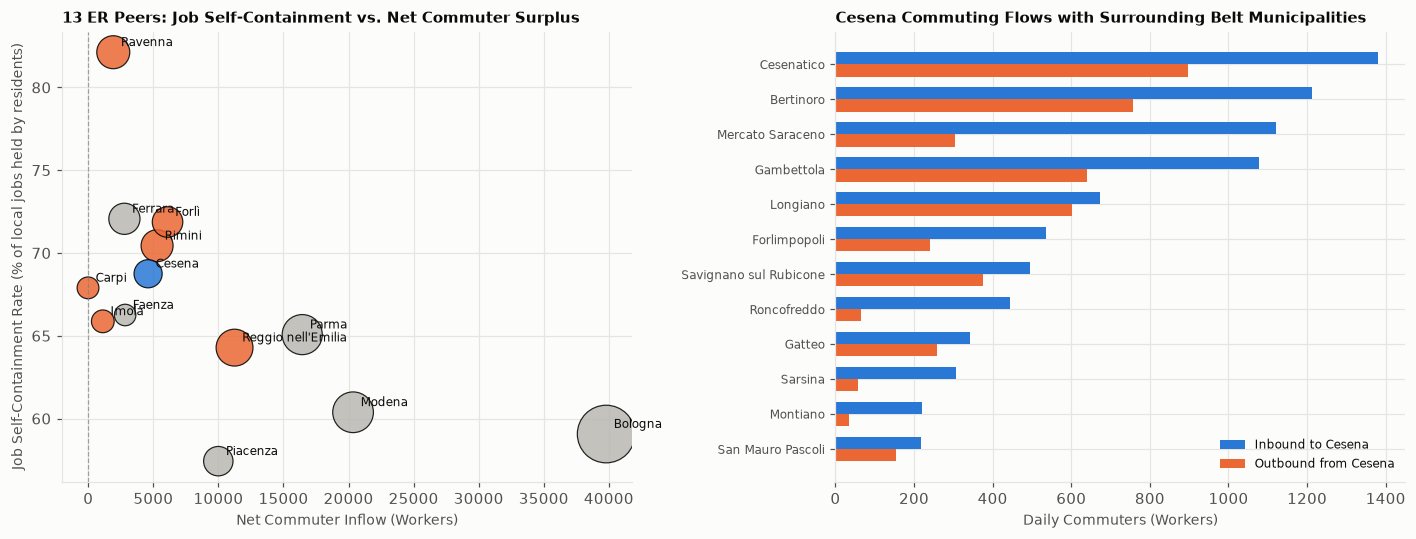

In [9]:
from cifresignificative.studies.cesena.analysis.commuting import (
    load_commuting_summary, peer_commuting_comparison,
    comprensorio_commuter_network, spatial_arbitrage_analysis,
)

df_sum = load_commuting_summary()
peer_comm = peer_commuting_comparison()
net_comm = comprensorio_commuter_network()
arb_comm = spatial_arbitrage_analysis()

print("1. Emilia-Romagna Peer Cities — Commuting Accounting & Self-Containment:")
display(peer_comm[[
    "name", "jobs_local", "resident_workers", "internal_workers", "net_commuter_inflow",
    "job_self_containment_rate", "labor_retention_rate", "commuter_inflow_ratio",
    "net_student_inflow", "pct_active", "pct_car", "pct_commute_le15m",
]].round(3))

print("\n2. Comprensorio Cesenate Functional Rings — Commuting Exchanges with Cesena:")
display(net_comm["ring_aggregates"][[
    "group_label", "inbound_to_cesena", "outbound_from_cesena", "net_inflow_to_cesena",
    "gross_commuter_flow", "study_inbound_to_cesena", "study_net_inflow_to_cesena",
]])

print("\n3. Top Commuting Corridors with Cesena (Belt Municipalities + Regional Neighbors):")
display(net_comm["municipal_flows"][[
    "partner_name", "group", "inbound_to_cesena", "outbound_from_cesena", "net_inflow_to_cesena",
    "gross_commuter_flow", "share_partner_resident_workers",
]].head(15).round(3))

print("\n4. Spatial Arbitrage: Housing Discount vs. Share Commuting to Cesena:")
display(arb_comm[[
    "name", "group", "share_partner_resident_workers", "inbound_to_cesena",
    "compr_mid_eur_m2", "price_discount_eur_m2", "purchase_savings_100m2",
    "loc_mid_eur_m2_mo", "rent_savings_80m2_annual",
]].round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 5.0))

# Left panel: Self-containment vs Net Commuter Inflow across 13 ER peers
x = peer_comm["net_commuter_inflow"]
y = peer_comm["job_self_containment_rate"] * 100.0
colors = [ITALY_C if row["is_cesena"] else (EU_C if row["is_core_peer"] else PEER_C) for _, row in peer_comm.iterrows()]
sizes = peer_comm["jobs_local"] / 1000.0 * 8.0

ax1.scatter(x, y, s=sizes, c=colors, alpha=0.85, edgecolors="black", linewidth=0.8)
for _, row in peer_comm.iterrows():
    ax1.annotate(row["name"], (row["net_commuter_inflow"], row["job_self_containment_rate"] * 100.0),
                 xytext=(5, 4), textcoords="offset points", fontsize=8)

ax1.axvline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
ax1.set_xlabel("Net Commuter Inflow (Workers)", fontsize=9)
ax1.set_ylabel("Job Self-Containment Rate (% of local jobs held by residents)", fontsize=9)
ax1.set_title("13 ER Peers: Job Self-Containment vs. Net Commuter Surplus", fontsize=10)

# Right panel: Bilateral Commuting Flows between Cesena and 16 Belt Municipalities
belt_corr = net_comm["municipal_flows"][net_comm["municipal_flows"]["group"].isin(["rubicone_mare", "via_emilia_west", "unione_valle_savio"])].head(12)
y_pos = np.arange(len(belt_corr))
h = 0.35

ax2.barh(y_pos - h/2, belt_corr["inbound_to_cesena"], height=h, color=ITALY_C, label="Inbound to Cesena")
ax2.barh(y_pos + h/2, belt_corr["outbound_from_cesena"], height=h, color=EU_C, label="Outbound from Cesena")
ax2.set_yticks(y_pos)
ax2.set_yticklabels(belt_corr["partner_name"], fontsize=8)
ax2.invert_yaxis()
ax2.set_xlabel("Daily Commuters (Workers)", fontsize=9)
ax2.set_title("Cesena Commuting Flows with Surrounding Belt Municipalities", fontsize=10)
ax2.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

## 8. Composition, Population Balance and Hypothesis Checks (2026-10-30 Review)

Income growth next to taxpayers and aggregate income, by period; population change split into natural balance, internal and international migration and registry adjustment (the four add up exactly); the 25–44 cohort by sub-period; and the housing check: the suburbanisation story predicts negative correlations.

In [10]:
P = "data/processed/cesena/"
display(pd.read_parquet(P + "income_composition.parquet").round(2))
bal = pd.read_parquet(P + "population_balance.parquet")
display(bal[bal["area"].isin(["cesena", "belt_16"])].drop(columns=["pop_start"]).round(1))
display(pd.read_parquet(P + "cohort_by_period.parquet").round(2))
display(pd.read_parquet(P + "housing_gradient_test.parquet").round(3))

,measure,t0,t1,cesena,rank,n,peer_median
0,mean_income,2008,2024,4.76,1,13,-0.90
1,mean_income,2008,2018,4.18,1,13,-0.08
2,mean_income,2018,2024,0.56,2,13,-1.22
3,median_income,2008,2024,7.58,1,13,0.75
4,median_income,2008,2018,6.91,1,13,0.39
5,median_income,2018,2024,0.63,7,13,0.71
6,taxpayers,2008,2024,0.50,10,13,1.29
7,taxpayers,2008,2018,-1.48,12,13,-0.46
8,taxpayers,2018,2024,2.01,6,13,1.81
9,aggregate_income,2008,2024,5.29,3,13,0.82


,area,t0,t1,pop_change,natural_balance,natural_balance_per_1k,net_migration_internal,net_migration_internal_per_1k,net_migration_international,net_migration_international_per_1k,registry_adjustment,registry_adjustment_per_1k,pop_change_per_1k
0,cesena,2008,2024,1267.0,-6549.0,-69.3,4560.0,48.3,4775.0,50.5,-1519.0,-16.1,13.4
1,cesena,2008,2011,2171.0,-739.0,-7.8,653.0,6.9,2257.0,23.9,0.0,0.0,23.0
2,cesena,2012,2018,787.0,-2312.0,-23.9,2209.0,22.9,890.0,9.2,0.0,0.0,8.1
3,cesena,2019,2024,-1691.0,-3498.0,-35.9,1698.0,17.4,1628.0,16.7,-1519.0,-15.6,-17.4
4,belt_16,2008,2024,9310.0,-3528.0,-27.6,7365.0,57.7,6847.0,53.6,-1374.0,-10.8,72.9
5,belt_16,2008,2011,7178.0,721.0,5.6,3243.0,25.4,3214.0,25.2,0.0,0.0,56.2
6,belt_16,2012,2018,1592.0,-998.0,-7.4,1834.0,13.6,756.0,5.6,0.0,0.0,11.8
7,belt_16,2019,2024,540.0,-3251.0,-23.8,2288.0,16.8,2877.0,21.1,-1374.0,-10.1,4.0


,t0,t1,cesena,rank,n,peer_median
0,2012,2024,7.98,13,13,12.65
1,2012,2016,0.92,13,13,13.20
2,2017,2024,12.39,9,13,13.82
3,2017,2019,18.71,5,13,15.86
4,2022,2024,11.64,12,13,17.31


,sample,x,y,n,spearman,p
0,belt_16,price,pop_growth_2008_2025,16,0.494,0.052
1,belt_16,price,pop_growth_2012_2024,16,0.609,0.012
2,belt_16,price,pop_growth_2019_2025,16,0.438,0.090
3,cities_13,price,cohort_25_44_2012_2024,13,0.049,0.873
4,cities_13,price,cohort_25_44_2017_2024,13,-0.258,0.394


## Income follow-up (6 November 2026)

Frozen national-price calculation; source components do not reconcile to an exhaustive total. Employment-and-assimilated income per recipient is not hourly wages or a longitudinal worker panel. Direct annual HICP levels and the current ECOICOP v2 series are sensitivity checks documented in `reports/income_evidence/`. Descriptive only.

In [11]:
from cifresignificative.studies.cesena.analysis.claims import income_followup_claims

price_basis = pd.read_csv("studies/cesena/reports/income_evidence/deflator_audit.csv").set_index("year")["panel_chained_2020_1"]
components = pd.read_parquet("data/processed/cesena/income_followup/income_components.parquet")
display(income_followup_claims(components, price_basis).round(2))

,comune_id,component,real_per_recipient_growth_pct,recipient_growth_pct,peer_median_growth_pct,peer_n
71,040007,reddito_dipendente,-1.68,12.30,-8.02,12
76,040007,reddito_pensione,25.58,-4.46,19.54,12


## Takeaways (Pillar 4 — Income & Demography; Descriptive)

- **Income is `robust` among the 13 cities.** Real mean and median income growth from 2008 rank first, but most of the lead predates 2019, and taxpayers grew slowly, so aggregate income does not rank first. IRPEF income is by residence, not workplace. Shares below a nominal threshold fall with inflation and are not results.
- **Ageing and weak population growth are `robust`.** Against the 16 surrounding towns, most of the gap comes from natural balance; moves within Italy were positive in Cesena in every period, and the towns' growth is concentrated in 2008–2011.
- **The 25–44 rank is `sensitive`.** Last place comes mostly from 2012–2016, and the measure contains registry revisions.
- **Suburbanisation is a `hypothesis` (research track R2).** Cheaper towns grew less, prices show no relation with the 25–44 cohort across cities, and no data here show who moves. The surcharge is owed where a taxpayer lives, so Cesena's lower rate favours living there.
- **Commuting (`context only`).** 2011 data; student flows cover all school levels.
- **University (`robust` as a description).** A small, specialised campus; graduate retention is not measured.
- **Limits.** All statements are descriptive associations for one municipality, never causal claims. The figures are in the table below and in `reports/findings.md`, both computed by `analysis/claims.py`.

In [12]:
from cifresignificative.studies.cesena.analysis.claims import claims_for_notebook

print("Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 60):
    display(claims_for_notebook("04"))

Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):


,id,text,window,source
0,income_mean_0824,+4.76%,2008-2024,income_composition.parquet
1,income_mean_0824_rank,#1 of 13,2008-2024,income_composition.parquet
2,income_mean_0824_peer,-0.90%,2008-2024,income_composition.parquet
3,income_mean_0818,+4.18%,2008-2018,income_composition.parquet
4,income_mean_0818_rank,#1 of 13,2008-2018,income_composition.parquet
5,income_mean_0818_peer,-0.08%,2008-2018,income_composition.parquet
6,income_mean_1824,+0.56%,2018-2024,income_composition.parquet
7,income_mean_1824_rank,#2 of 13,2018-2024,income_composition.parquet
8,income_mean_1824_peer,-1.22%,2018-2024,income_composition.parquet
9,income_median_0824,+7.58%,2008-2024,income_composition.parquet
